In [ ]:
import re, json, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lxml import etree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Wczytanie danych

`SOURCES` wybiera, które części korpusu wczytać. Domyślnie tylko **posiedzenia plenarne Sejmu** (203 pliki, ok. 170 MB), czyli mowa żywa i najbardziej nadająca się do anotacji postaw.
Pozostałe części:
- `sejm/komisje`: posiedzenia komisji (ok. 5,5 tys. plików, 650 MB), też mowa żywa, ale parsowanie trwa kilka minut
- `senat/posiedzenia`, `senat/komisje`: Senat
- `sejm/interpelacje`: **celowo pominięte**, to ok. 50 tys. pism urzędowych (odpowiedzi ministerstw), a nie wypowiedzi

In [2]:
DATA_ROOT = Path("2023-2027")          # katalog z rozpakowanego korpusu (względem notebooka)
SOURCES = ["sejm/posiedzenia"]         # np. dodaj "sejm/komisje", "senat/posiedzenia"
CACHE = Path(f"ppc_cache_{'_'.join(s.replace('/', '-') for s in SOURCES)}.pkl.gz")
REBUILD = False                        # True wymusza ponowne parsowanie XML
assert DATA_ROOT.exists(), f"Brak katalogu {DATA_ROOT.resolve()}"

In [3]:
NS = {"t": "http://www.tei-c.org/ns/1.0"}
XML_ID = "{http://www.w3.org/XML/1998/namespace}id"

CLUB_RULES = [
    ("PrawoiSprawiedliwosc", "PiS"),
    ("KoalicjaObywatelska", "KO"),
    ("Konfederacja", "Konfederacja"),
    ("PolskieStronnictwoLudowe", "PSL-TD"),
    ("Polska2050", "Polska2050-TD"),
    ("Lewicy", "Lewica"),
    ("Kukiz", "Kukiz'15"),
    ("Razem", "Razem"),
    ("Niezrzeszeni", "niezrzeszeni"),
]


def short_club(ref):
    if not ref:
        return None
    ref = ref.lstrip("#")
    for key, name in CLUB_RULES:
        if key in ref:
            return name
    return ref[:25]


def parse_header(path):
    root = etree.parse(str(path)).getroot()
    meta = {
        n.get("type"): (n.text or "").strip()
        for n in root.iterfind(".//t:bibl/t:note", NS)
    }
    date = root.findtext(".//t:bibl/t:date", namespaces=NS)
    people = {}
    for p in root.iterfind(".//t:listPerson/t:person", NS):
        pid = p.get(XML_ID)
        fn = p.findtext("t:persName/t:forename", namespaces=NS) or ""
        sn = p.findtext("t:persName/t:surname", namespaces=NS) or ""
        role_name = p.findtext("t:persName/t:roleName", namespaces=NS) or ""
        aff = p.find("t:affiliation", NS)
        sex = p.find("t:sex", NS)
        people[pid] = dict(
            speaker=(f"{fn} {sn}".strip() or role_name or pid),
            person_role=p.get("role"),
            role_name=role_name,
            club=short_club(aff.get("ref")) if aff is not None else None,
            sex=sex.get("value") if sex is not None else None,
        )
    return meta, date, people


def parse_doc(doc_dir, source):
    meta, date, people = parse_header(doc_dir / "header.xml")
    body = etree.parse(str(doc_dir / "text_structure.xml")).getroot()
    rows = []
    for turn_no, div in enumerate(body.iterfind(".//t:body/t:div", NS)):
        for u in div.iterfind("t:u", NS):
            who = (u.get("who") or "").lstrip("#")
            text = " ".join("".join(u.itertext()).split())
            info = people.get(who, {})
            rows.append(
                dict(
                    source=source,
                    doc=doc_dir.name,
                    date=date,
                    house=meta.get("house"),
                    sess_type=meta.get("type"),
                    session=meta.get("sessionNo"),
                    day=meta.get("dayNo"),
                    turn=f"{doc_dir.name}#{turn_no}",
                    who=who,
                    text=text,
                    speaker=info.get("speaker", who),
                    person_role=info.get("person_role"),
                    role_name=info.get("role_name"),
                    club=info.get("club"),
                    sex=info.get("sex"),
                )
            )
    return rows


df = None
if CACHE.exists() and not REBUILD:
    try:
        df = pd.read_pickle(CACHE)
        print("Wczytano cache:", CACHE)
    except Exception as e:  # np. inna wersja pandas niż ta, która zapisała cache
        print("Cache nieczytelny, parsuję od nowa:", type(e).__name__)

if df is None:
    rows = []
    for src in SOURCES:
        docs = sorted(p.parent for p in (DATA_ROOT / src).rglob("text_structure.xml"))
        print(f"{src}: {len(docs)} dokumentów")
        for i, d in enumerate(docs, 1):
            rows.extend(parse_doc(d, src))
            if i % 500 == 0:
                print(f"  ...{i}/{len(docs)}")
    df = pd.DataFrame(rows)
    df["date"] = pd.to_datetime(df["date"])
    try:
        df.to_pickle(CACHE)
        print("Zapisano cache:", CACHE)
    except Exception as e:
        print("Nie udało się zapisać cache:", e)
df["date"] = pd.to_datetime(df["date"])
df.shape

Wczytano cache: ppc_cache_sejm-posiedzenia.pkl.gz


(510173, 15)

### Cechy pomocnicze

- `is_comment`: didaskalia/uwagi stenografa (`who="#komentarz"`), np. *(Oklaski)*. To nie wypowiedzi.
- `is_chair`: prowadzący obrady (Marszałek/Wicemarszałek/przewodniczący), głównie formuły proceduralne.
- `is_speech`: właściwa wypowiedź (nie komentarz).

In [4]:
TOKEN = re.compile(r"\w+", re.UNICODE)
SENT_END = re.compile(r"[.!?…]+(?:\s|$)")

df["n_chars"] = df["text"].str.len()
df["tokens"] = df["text"].str.lower().map(TOKEN.findall)
df["n_words"] = df["tokens"].map(len)
df["n_sent"] = df["text"].map(lambda s: max(1, len(SENT_END.findall(s))))

df["is_comment"] = df["who"].eq("komentarz")
chair_re = re.compile(r"marsza|przewodnicz|prezes|prowadz", re.I)
df["is_chair"] = (
    df["who"].eq("Marszalek")
    | df["role_name"].fillna("").str.contains(chair_re) & ~df["is_comment"]
)
df["is_speech"] = ~df["is_comment"]
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
df[["speaker", "club", "role_name", "date", "n_words", "text"]].sample(
    5, random_state=0
)

,speaker,club,role_name,date,n_words,text
191155,Maria Koźlakiewicz,KO,Poseł,2025-01-24,32,"Jako parlamentarzyści musimy kontynuować działania, które mają na celu poprawę warunków prowadzenia działalności gos..."
378536,Tadeusz Tomaszewski,Lewica,Poseł,2026-02-13,50,"Projekt ustawy zakłada również zrównanie ochrony przysługującej sędziom sportowym z ochroną, jaką objęci są funkcjon..."
376716,Marszałek,NaN,Marszałek,2026-02-13,23,"Proszę bardzo, jeszcze chwila, jeszcze moment. Nie: nie działa, tylko nie zdążył poseł, ale poczekamy. Panie pośle, ..."
379811,Monika Wielichowska,KO,Wicemarszałek,2026-02-25,8,Ostatnie pytanie należy do pani poseł Krystyny Szumilas.
423128,Dorota Niedziela,KO,Wicemarszałek,2026-05-13,8,Głos zabierze sprawozdawca komisji pan poseł Henryk Szopiński.


## 2. Podstawowe liczby

In [5]:
sp = df[df["is_speech"]]
all_tokens = Counter(t for toks in sp["tokens"] for t in toks)

summary = pd.Series({
    "dokumenty (dni obrad)": df["doc"].nunique(),
    "zakres dat": f"{df['date'].min():%Y-%m-%d} – {df['date'].max():%Y-%m-%d}",
    "jednostki <u> (razem)": len(df),
    "  w tym komentarze": int(df["is_comment"].sum()),
    "  w tym wypowiedzi": len(sp),
    "wystąpienia (div, bez komentarzy)": sp["turn"].nunique(),
    "unikalni mówcy": sp["who"].nunique(),
    "słowa (tokeny) w wypowiedziach": sum(all_tokens.values()),
    "słownik (typy)": len(all_tokens),
    "znaki w wypowiedziach": int(sp["n_chars"].sum()),
})
summary.to_frame("wartość")

,wartość
dokumenty (dni obrad),203
zakres dat,2023-11-13 – 2026-10-09
jednostki <u> (razem),510173
w tym komentarze,103054
w tym wypowiedzi,407119
"wystąpienia (div, bez komentarzy)",107594
unikalni mówcy,645
słowa (tokeny) w wypowiedziach,14723160
słownik (typy),209242
znaki w wypowiedziach,105156863


In [6]:
# jakość metadanych: ilu mówców ma przypisany klub / płeć
spk = sp.drop_duplicates("who")
pd.DataFrame({
    "udział mówców z klubem": [spk["club"].notna().mean()],
    "udział mówców z płcią": [spk["sex"].notna().mean()],
    "udział wypowiedzi z klubem": [sp["club"].notna().mean()],
}).T.rename(columns={0: "udział"})

,udział
udział mówców z klubem,0.76
udział mówców z płcią,0.99
udział wypowiedzi z klubem,0.80


## 3. Kto mówi: mówcy i ich wypowiedzi

Rozkład jest silnie skośny: kilkoro prowadzących obrady i kilkunastu aktywnych posłów generuje bardzo dużo jednostek, a większość osób wypowiada się rzadko. Dlatego wykresy rysujemy też w skali logarytmicznej.

In [7]:
# klucz = identyfikator mówcy (rola i klub mogą się różnić między dokumentami, więc bierzemy wartość najczęstszą)
mode = lambda s: s.mode().iloc[0] if s.notna().any() else None
per_speaker = (sp.groupby("who")
                 .agg(speaker=("speaker", "first"), club=("club", mode), role_name=("role_name", mode),
                      units=("text", "size"), turns=("turn", "nunique"),
                      words=("n_words", "sum"), is_chair=("is_chair", "max"))
                 .reset_index().sort_values("units", ascending=False))
per_speaker["share_units_%"] = 100 * per_speaker["units"] / per_speaker["units"].sum()
per_speaker["cum_share_%"] = per_speaker["share_units_%"].cumsum()
per_speaker.head(15)

,who,speaker,club,role_name,units,turns,words,is_chair,share_units_%,cum_share_%
408,Marszalek,Marszałek,NaN,Marszałek,62543,4337,661701,True,15.36,15.36
452,MonikaWielichowska,Monika Wielichowska,KO,Wicemarszałek,33494,13222,276250,True,8.23,23.59
134,DorotaNiedziela,Dorota Niedziela,KO,Wicemarszałek,26561,9692,260168,True,6.52,30.11
287,KrzysztofBosak,Krzysztof Bosak,Konfederacja,Wicemarszałek,25483,8201,205622,True,6.26,36.37
503,PiotrZgorzelski,Piotr Zgorzelski,PSL-TD,Wicemarszałek,20294,8794,172118,True,4.98,41.36
618,WlodzimierzCzarzasty,Włodzimierz Czarzasty,Lewica,Wicemarszałek,14519,4737,96809,True,3.57,44.92
566,SzymonHolownia,Szymon Hołownia,Polska2050-TD,Wicemarszałek,12199,3647,102167,True,3.00,47.92
356,MarcinJozefaciuk,Marcin Józefaciuk,KO,Poseł,5680,1325,244609,False,1.40,49.32
219,JaroslawSachajko,Jarosław Sachajko,Kukiz'15,Poseł,4757,1579,292517,False,1.17,50.48
610,WitoldTumanowicz,Witold Tumanowicz,Konfederacja,Poseł,4340,1743,284688,False,1.07,51.55


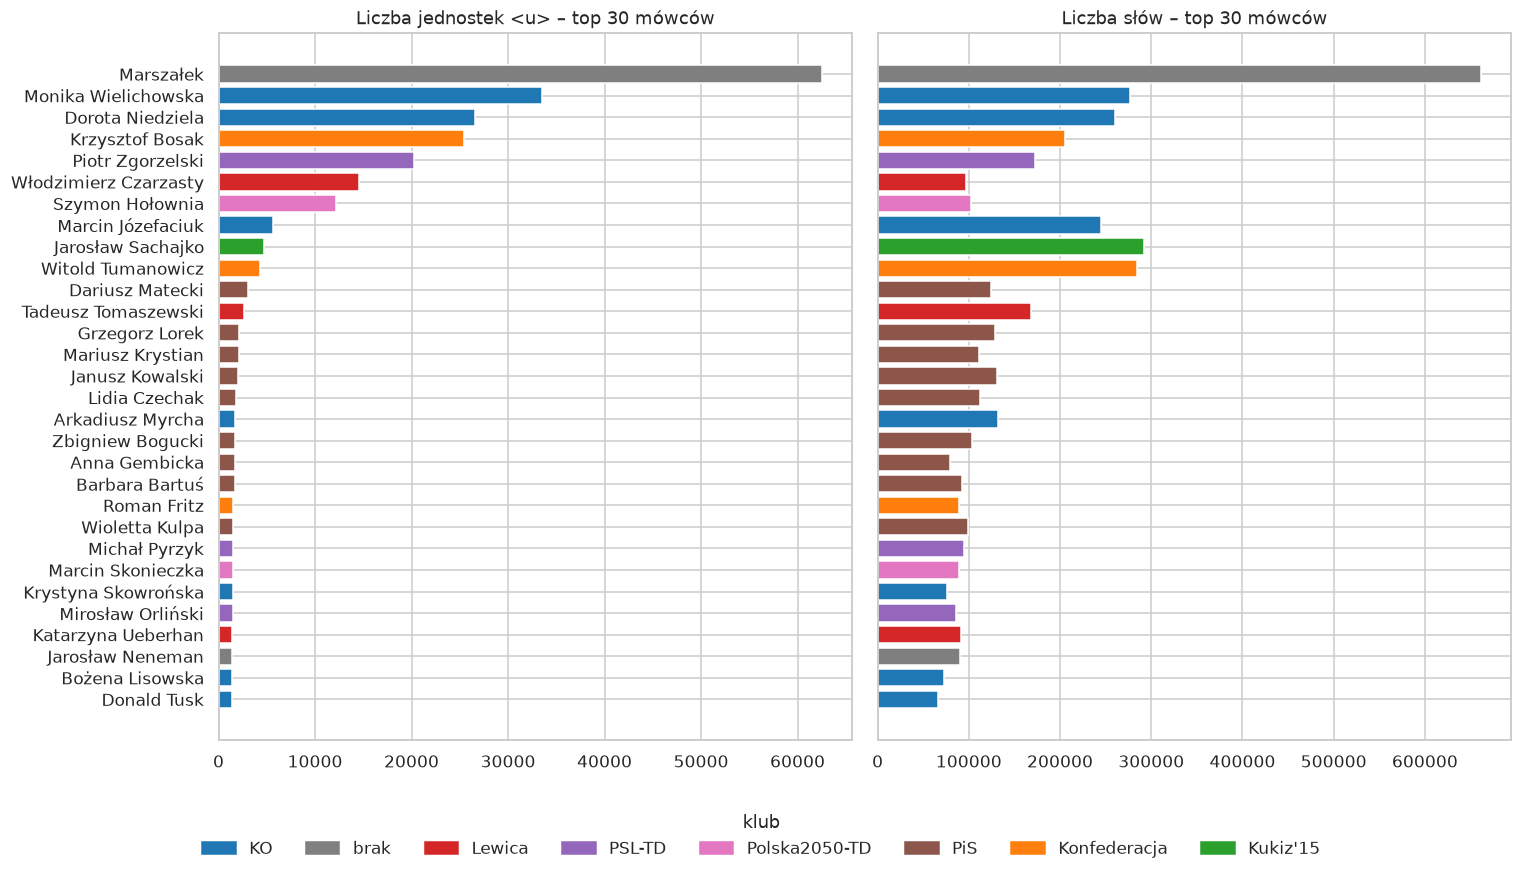

In [8]:
TOP = 30
top = per_speaker.head(TOP).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
colors = top["club"].fillna("brak").map(dict(zip(sorted(per_speaker["club"].fillna("brak").unique()),
                                                 sns.color_palette("tab10", per_speaker["club"].nunique() + 1))))
ax[0].barh(top["speaker"], top["units"], color=colors)
ax[0].set_title(f"Liczba jednostek <u> – top {TOP} mówców")
ax[1].barh(top["speaker"], top["words"], color=colors)
ax[1].set_title(f"Liczba słów – top {TOP} mówców")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in
           dict.fromkeys(colors)]
labels = list(dict.fromkeys(top["club"].fillna("brak")))
fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 9), title="klub", frameon=False)
plt.tight_layout(rect=(0, 0.09, 1, 1)); plt.show()

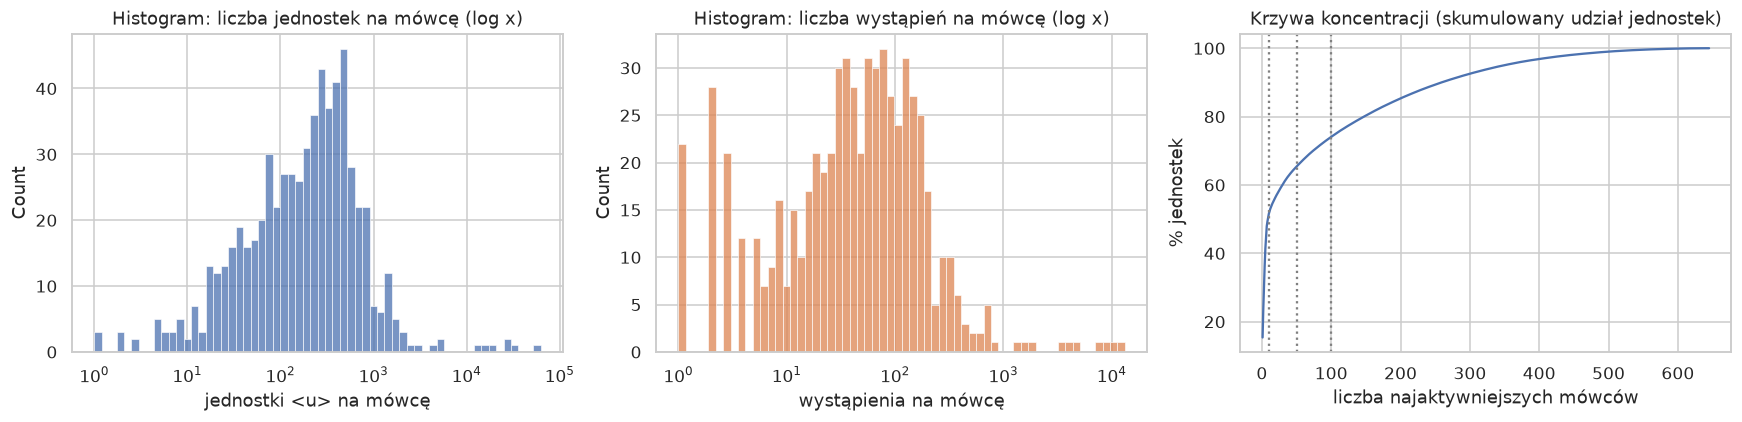

mediana jednostek na mówcę: 206, średnia: 631.2, maks.: 62543
mówcy z <= 5 jednostkami: 2%


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(per_speaker["units"], bins=60, log_scale=(True, False), ax=ax[0])
ax[0].set_title("Histogram: liczba jednostek na mówcę (log x)")
ax[0].set_xlabel("jednostki <u> na mówcę")
sns.histplot(per_speaker["turns"], bins=60, log_scale=(True, False), ax=ax[1], color="C1")
ax[1].set_title("Histogram: liczba wystąpień na mówcę (log x)")
ax[1].set_xlabel("wystąpienia na mówcę")
ax[2].plot(np.arange(1, len(per_speaker) + 1), per_speaker["cum_share_%"])
ax[2].set_title("Krzywa koncentracji (skumulowany udział jednostek)")
ax[2].set_xlabel("liczba najaktywniejszych mówców"); ax[2].set_ylabel("% jednostek")
for k in (10, 50, 100):
    ax[2].axvline(k, ls=":", c="gray")
    ax[2].annotate(f"{per_speaker['cum_share_%'].iloc[min(k, len(per_speaker)) - 1]:.0f}%", (k, 5))
plt.tight_layout(); plt.show()

print(f"mediana jednostek na mówcę: {per_speaker['units'].median():.0f}, "
      f"średnia: {per_speaker['units'].mean():.1f}, maks.: {per_speaker['units'].max()}")
print(f"mówcy z <= 5 jednostkami: {(per_speaker['units'] <= 5).mean():.0%}")

### Mówcy prowadzący a pozostali

Prowadzący obrady (marszałek, wicemarszałkowie) mówią dużo, ale głównie proceduralnie (*„Głos ma pan poseł…”*). W anotacji postaw warto ich wykluczyć lub zaznaczyć osobno.

In [10]:
g = sp.groupby("is_chair").agg(units=("text", "size"), words=("n_words", "sum"),
                               speakers=("who", "nunique"), median_len=("n_words", "median"))
g.index = g.index.map({True: "prowadzący obrady", False: "pozostali"})
g["% jednostek"] = 100 * g["units"] / g["units"].sum()
g

,units,words,speakers,median_len,% jednostek
is_chair,,,,,
pozostali,212212,12732270,618,49.00,52.13
prowadzący obrady,194907,1990890,44,6.00,47.87


## 4. Rozkład długości wypowiedzi

Dwa poziomy: **jednostka `<u>`** (zdanie/akapit) i **wystąpienie** (wszystkie jednostki jednego mówcy w jednym `<div>`).

In [11]:
def describe(s):
    q = s.quantile([.05, .25, .5, .75, .95, .99])
    return pd.Series({"n": len(s), "średnia": s.mean(), "odch. std.": s.std(), "min": s.min(),
                      **{f"p{int(k*100)}": v for k, v in q.items()}, "max": s.max()})

turns = (sp.groupby("turn")
           .agg(speaker=("speaker", "first"), club=("club", "first"), is_chair=("is_chair", "first"),
                date=("date", "first"), units=("text", "size"), words=("n_words", "sum"),
                chars=("n_chars", "sum"), text=("text", " ".join))
           .reset_index())

pd.DataFrame({
    "jednostka <u>: słowa": describe(sp["n_words"]),
    "jednostka <u>: znaki": describe(sp["n_chars"]),
    "jednostka <u>: zdania": describe(sp["n_sent"]),
    "wystąpienie: słowa": describe(turns["words"]),
    "wystąpienie: jednostki <u>": describe(turns["units"]),
})

,jednostka <u>: słowa,jednostka <u>: znaki,jednostka <u>: zdania,wystąpienie: słowa,wystąpienie: jednostki <u>
n,"407,119.00","407,119.00","407,119.00","107,594.00","107,594.00"
średnia,36.16,258.30,3.08,136.84,3.78
odch. std.,45.08,321.34,3.17,233.53,7.71
min,0.00,1.00,1.00,1.00,1.00
p5,2.00,14.00,1.00,5.00,1.00
p25,5.00,33.00,1.00,11.00,2.00
p50,16.00,108.00,2.00,56.00,2.00
p75,53.00,382.00,4.00,160.00,4.00
p95,129.00,919.10,10.00,555.00,10.00
p99,193.00,"1,373.00",15.00,"1,158.00",23.00


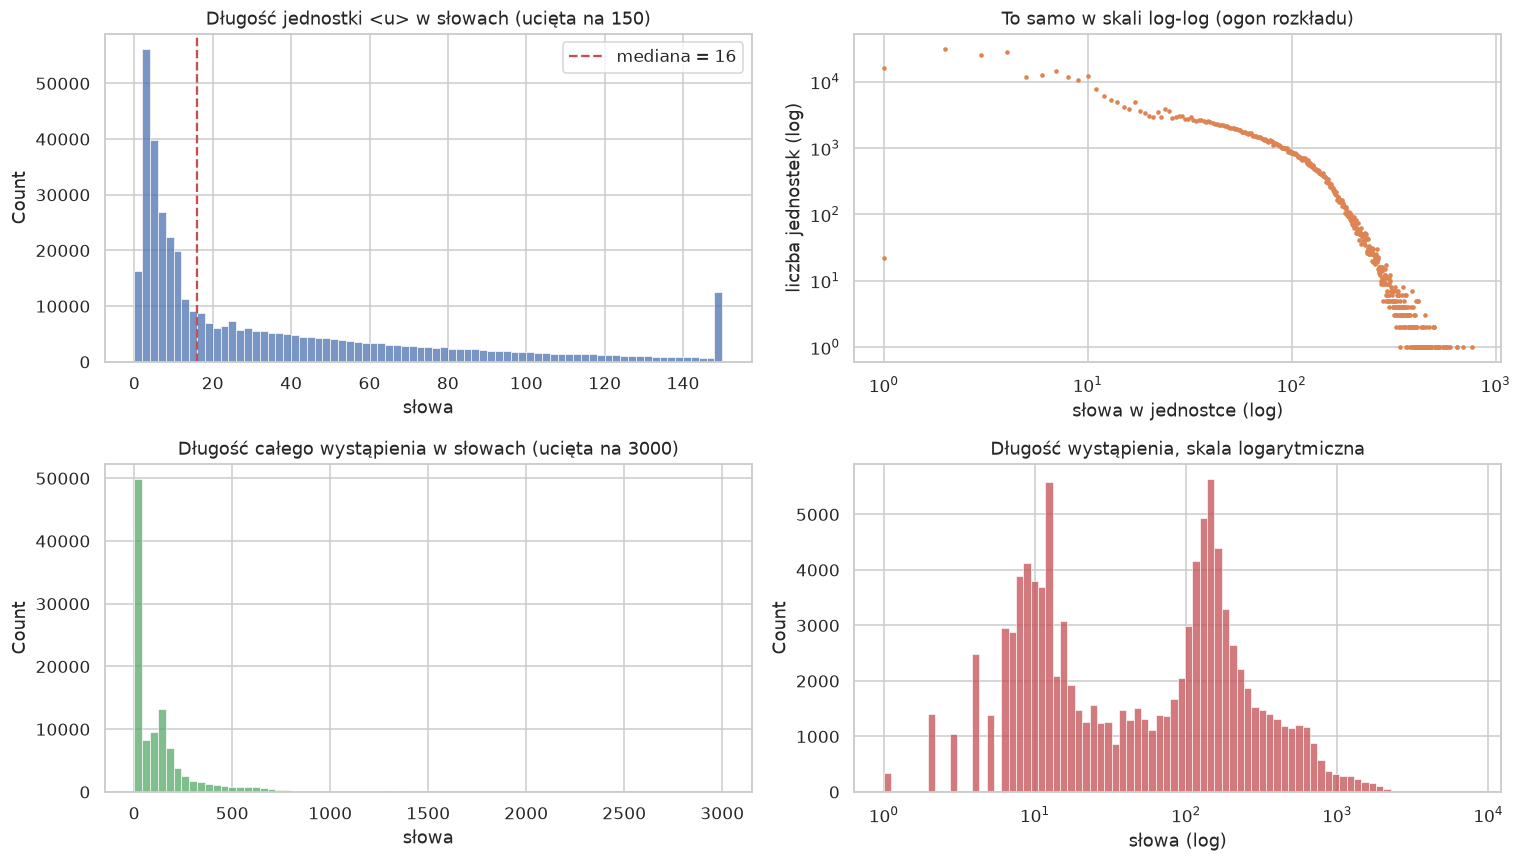

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(sp["n_words"].clip(upper=150), bins=75, ax=ax[0, 0])
ax[0, 0].set_title("Długość jednostki <u> w słowach (ucięta na 150)")
ax[0, 0].axvline(sp["n_words"].median(), c="r", ls="--", label=f"mediana = {sp['n_words'].median():.0f}")
ax[0, 0].legend(); ax[0, 0].set_xlabel("słowa")

vc = sp["n_words"].value_counts().sort_index()
ax[0, 1].loglog(np.maximum(vc.index.values, 1), vc.values, ".", ms=4, color="C1")
ax[0, 1].set_title("To samo w skali log-log (ogon rozkładu)")
ax[0, 1].set_xlabel("słowa w jednostce (log)"); ax[0, 1].set_ylabel("liczba jednostek (log)")

sns.histplot(turns["words"].clip(upper=3000), bins=75, ax=ax[1, 0], color="C2")
ax[1, 0].set_title("Długość całego wystąpienia w słowach (ucięta na 3000)")
ax[1, 0].set_xlabel("słowa")

sns.histplot(turns["words"], bins=80, log_scale=(True, False), ax=ax[1, 1], color="C3")
ax[1, 1].set_title("Długość wystąpienia, skala logarytmiczna")
ax[1, 1].set_xlabel("słowa (log)")
plt.tight_layout(); plt.show()

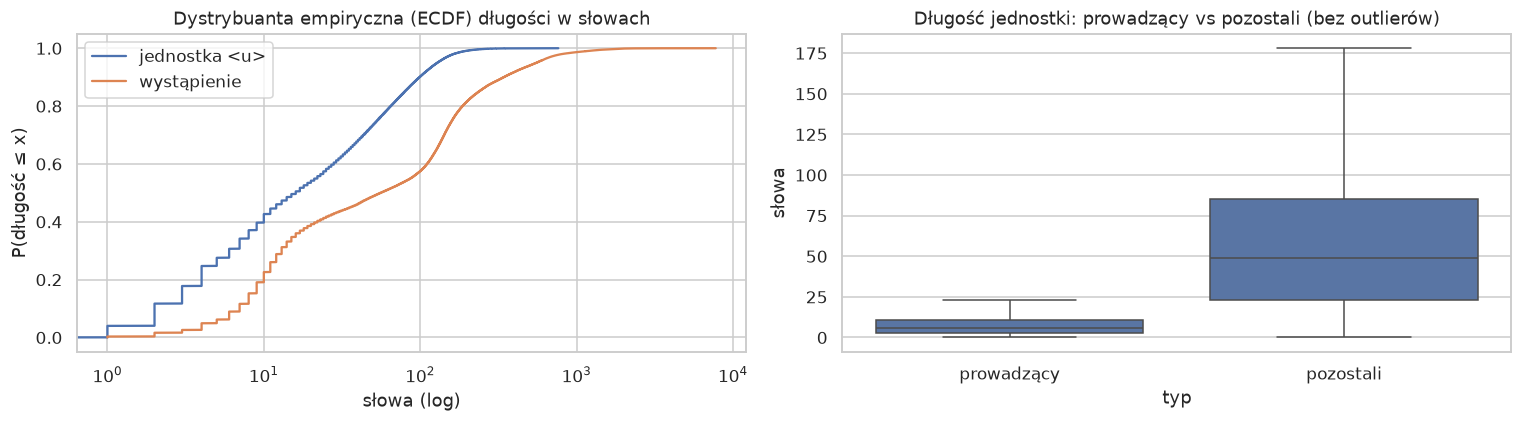

,% jednostek
n_words,
1-3,17.80
4-7,16.40
8-15,15.40
16-30,12.30
31-60,16.30
61-120,15.60
>120,6.10


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, s in [("jednostka <u>", sp["n_words"]), ("wystąpienie", turns["words"])]:
    x = np.sort(s.values); ax[0].plot(x, np.arange(1, len(x) + 1) / len(x), label=name)
ax[0].set_xscale("log"); ax[0].set_title("Dystrybuanta empiryczna (ECDF) długości w słowach")
ax[0].set_xlabel("słowa (log)"); ax[0].set_ylabel("P(długość ≤ x)"); ax[0].legend()

sns.boxplot(data=sp.assign(typ=np.where(sp["is_chair"], "prowadzący", "pozostali")),
            x="typ", y="n_words", showfliers=False, ax=ax[1])
ax[1].set_title("Długość jednostki: prowadzący vs pozostali (bez outlierów)")
ax[1].set_ylabel("słowa")
plt.tight_layout(); plt.show()

bins = [0, 3, 7, 15, 30, 60, 120, np.inf]
lab = ["1-3", "4-7", "8-15", "16-30", "31-60", "61-120", ">120"]
(pd.cut(sp["n_words"], bins=bins, labels=lab).value_counts(normalize=True).reindex(lab)
   .mul(100).round(1).rename("% jednostek").to_frame())

Jednostki bardzo krótkie (1-3 słowa) to typowo formuły: *„Dziękuję.”*, *„Dzień dobry państwu.”*, *„Proszę bardzo.”*. Najczęstsze z nich pokazuje następna komórka.

In [18]:
(sp["text"].value_counts().head(50).rename("liczba").to_frame())

,liczba
text,
Dziękuję.,10991
Dziękuję bardzo.,10690
"Dziękuję bardzo, panie pośle.",6137
Bardzo dziękuję.,5357
Bardzo proszę.,4864
Kto się wstrzymał?,4835
Kto jest przeciw?,4754
"Dziękuję bardzo, pani poseł.",3746
Proszę bardzo.,2687


## 5. Kluby, role, płeć i czas

In [22]:
by_club = (sp[~sp["is_chair"]].groupby(sp["club"].fillna("brak / gość"))
             .agg(mówcy=("who", "nunique"), jednostki=("text", "size"), słowa=("n_words", "sum"),
                  mediana_długości=("n_words", "median"))
             .sort_values("słowa", ascending=False))
by_club["słowa / mówcę"] = by_club["słowa"] / by_club["mówcy"]
by_club

,mówcy,jednostki,słowa,mediana_długości,słowa / mówcę
club,,,,,
PiS,192,61744,3587056,47.00,"18,682.58"
KO,176,64158,3511148,43.00,"19,949.70"
brak / gość,127,15967,1220713,66.00,"9,611.91"
Polska2050-TD,35,18456,1151564,52.00,"32,901.83"
Lewica,30,15469,1029589,56.00,"34,319.63"
Konfederacja,21,15916,974379,51.00,"46,399.00"
PSL-TD,34,15044,928161,51.00,"27,298.85"
Kukiz'15,3,5458,329660,53.00,"109,886.67"


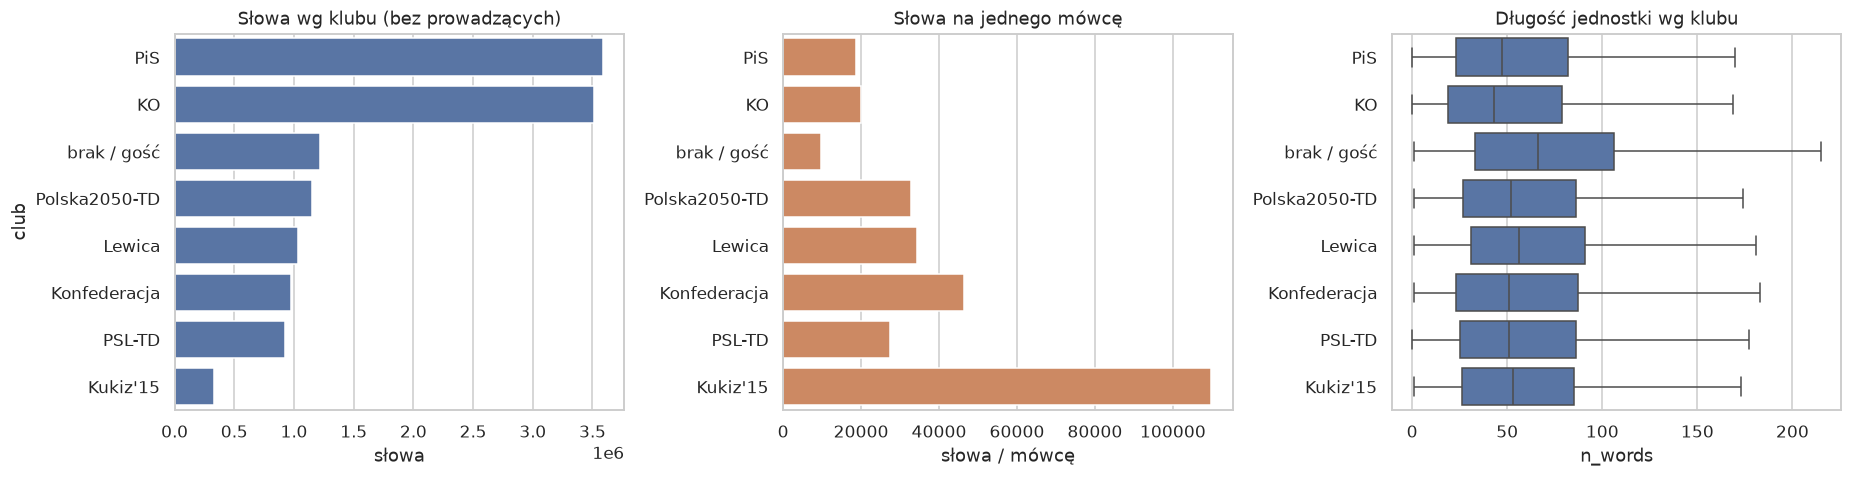

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
order = by_club.index
sns.barplot(x=by_club["słowa"], y=by_club.index, ax=ax[0], color="C0")
ax[0].set_title("Słowa wg klubu (bez prowadzących)")
sns.barplot(x=by_club["słowa / mówcę"], y=by_club.index, ax=ax[1], color="C1")
ax[1].set_title("Słowa na jednego mówcę"); ax[1].set_ylabel("")
sns.boxplot(data=sp[~sp["is_chair"]].assign(klub=sp["club"].fillna("brak / gość")),
            y="klub", x="n_words", order=order, showfliers=False, ax=ax[2])
ax[2].set_title("Długość jednostki wg klubu"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()

In [24]:
role = sp.assign(grupa=np.select(
    [sp["is_chair"], sp["person_role"].eq("guest"), sp["club"].notna()],
    ["prowadzący", "gość (minister, urzędnik, inni)", "poseł (z klubem)"], "pozostali"))
t = role.groupby("grupa").agg(mówcy=("who", "nunique"), jednostki=("text", "size"),
                              słowa=("n_words", "sum"), mediana_długości=("n_words", "median"))
t["% słów"] = 100 * t["słowa"] / t["słowa"].sum()
display(t)

sex = sp[sp["sex"].notna() & ~sp["is_chair"]].groupby("sex").agg(
    mówcy=("who", "nunique"), jednostki=("text", "size"), słowa=("n_words", "sum"),
    mediana_długości=("n_words", "median"))
sex.index = [{"F": "kobiety", "M": "mężczyźni"}.get(i, i) for i in sex.index]
sex["słowa / mówcę"] = sex["słowa"] / sex["mówcy"]
sex

,mówcy,jednostki,słowa,mediana_długości,% słów
grupa,,,,,
"gość (minister, urzędnik, inni)",117,14660,1136958,67.00,7.72
poseł (z klubem),491,196245,11511557,48.00,78.19
pozostali,10,1307,83755,56.00,0.57
prowadzący,44,194907,1990890,6.00,13.52


,mówcy,jednostki,słowa,mediana_długości,słowa / mówcę
kobiety,194,65049,3792012,48.00,"19,546.45"
mężczyźni,418,146840,8936737,49.00,"21,379.75"


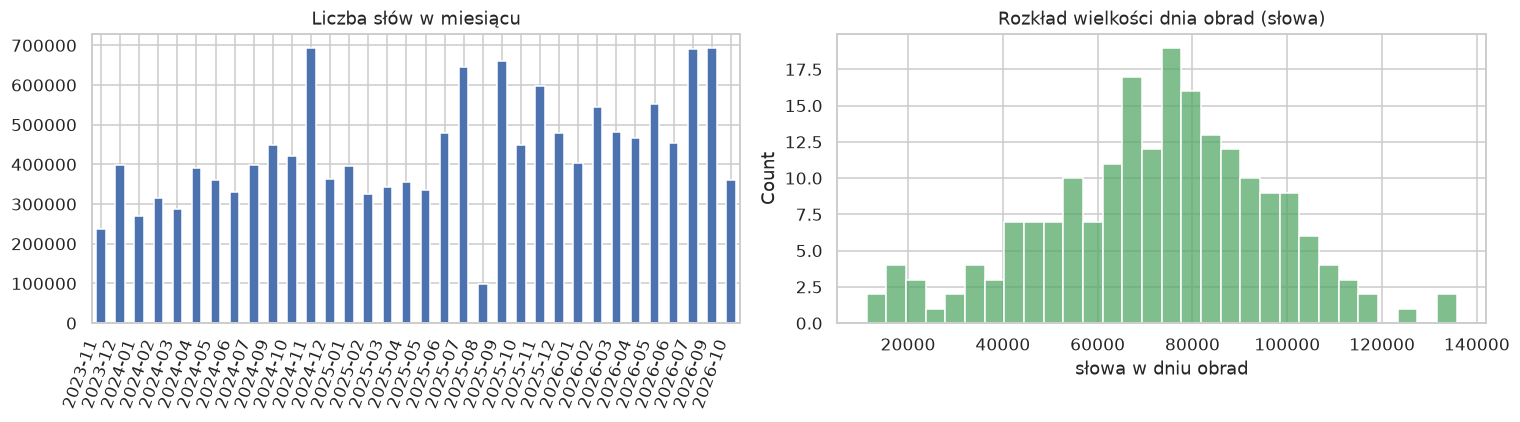

In [25]:
monthly = sp.groupby("month").agg(słowa=("n_words", "sum"), dni=("doc", "nunique"),
                                  mówcy=("who", "nunique"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly["słowa"].plot(kind="bar", ax=ax[0], color="C0")
ax[0].set_xticklabels([d.strftime("%Y-%m") for d in monthly.index], rotation=70, ha="right")
ax[0].set_title("Liczba słów w miesiącu"); ax[0].set_xlabel("")
daily = sp.groupby("doc").agg(słowa=("n_words", "sum"))
sns.histplot(daily["słowa"], bins=30, ax=ax[1], color="C2")
ax[1].set_title("Rozkład wielkości dnia obrad (słowa)"); ax[1].set_xlabel("słowa w dniu obrad")
plt.tight_layout(); plt.show()

## 6. Słownictwo

Prosta tokenizacja (`\w+`, małe litery), bez lematyzacji. Polski jest silnie fleksyjny, więc liczba typów jest zawyżona w stosunku do liczby leksemów. To też argument za tym, by w części II porównać fastText (sub-słowa) z Word2Vec.

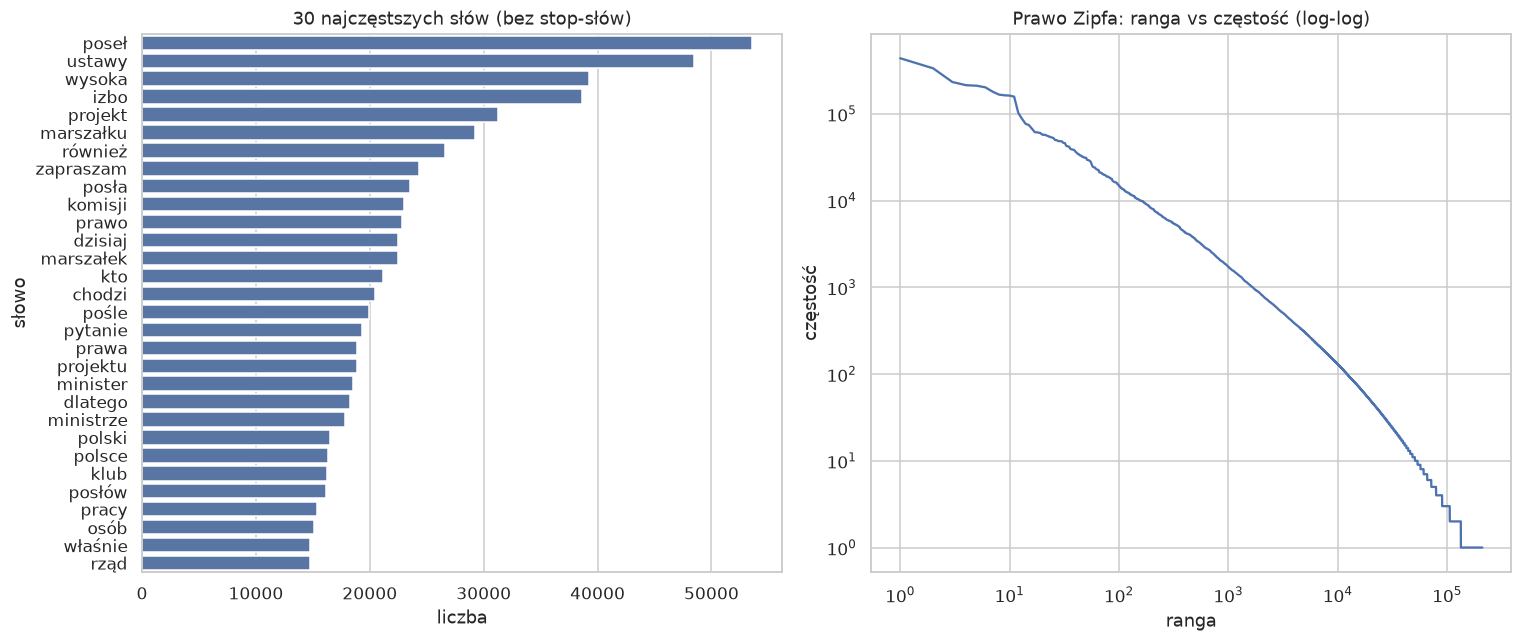

In [26]:
STOP = set('''i w we z ze na do o od po za u a oraz lub albo ale że żeby aby by się nie to jest są był była było byli były
będzie będą tak jak już też także tylko jeszcze czy co który która które którzy którego której którym którą których
ten ta te tego tej tym ci tych tę ich go mu mi mnie ci cię nas nam wam was wy my on ona oni one ono im jej jego
pan pani państwo państwa panie pana panu panią panów pań panowie proszę bardzo dziękuję
przez dla pod nad przed między bez przy jako więc bo gdy gdyby jeśli jeżeli kiedy gdzie tu tam tutaj teraz
bardzo może można trzeba mamy mają ma mieć mam być by nich nim niej niego nią niech sobie tego tym tych
wszystko wszyscy wszystkich wszystkim każdy każda każde jeden jedna jedno dwa dwie trzy
roku lat lata rok r'''.split())

content = Counter({w: c for w, c in all_tokens.items() if w not in STOP and not w.isdigit() and len(w) > 2})
top_words = pd.DataFrame(content.most_common(30), columns=["słowo", "liczba"])
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_words, y="słowo", x="liczba", ax=ax[0], color="C0")
ax[0].set_title("30 najczęstszych słów (bez stop-słów)")

ranks = np.arange(1, len(all_tokens) + 1)
freqs = np.array(sorted(all_tokens.values(), reverse=True))
ax[1].loglog(ranks, freqs)
ax[1].set_title("Prawo Zipfa: ranga vs częstość (log-log)")
ax[1].set_xlabel("ranga"); ax[1].set_ylabel("częstość")
plt.tight_layout(); plt.show()

In [27]:
N = sum(all_tokens.values()); V = len(all_tokens)
hapax = sum(1 for c in all_tokens.values() if c == 1)
first100k = [t for toks in sp["tokens"] for t in toks][:100_000]   # TTR zależy od N, więc podajemy też wartość dla stałej próbki
freq_arr = np.array(list(all_tokens.values()))
pd.Series({
    "tokeny N": N,
    "typy V": V,
    "TTR = V/N": f"{V / N:.4f}",
    "TTR dla pierwszych 100 tys. tokenów": f"{len(set(first100k)) / len(first100k):.4f}",
    "hapax legomena (1 wystąpienie)": hapax,
    "hapax jako % słownika": 100 * hapax / V,
    "słów potrzebnych na 50% tokenów": int((np.cumsum(np.sort(freq_arr)[::-1]) < 0.5 * N).sum() + 1),
    "słów potrzebnych na 90% tokenów": int((np.cumsum(np.sort(freq_arr)[::-1]) < 0.9 * N).sum() + 1),
    "typy z min. 5 wystąpieniami": int((freq_arr >= 5).sum()),
}).to_frame("wartość")

,wartość
tokeny N,14723160
typy V,209242
TTR = V/N,0.0142
TTR dla pierwszych 100 tys. tokenów,0.1549
hapax legomena (1 wystąpienie),76169
hapax jako % słownika,36.40
słów potrzebnych na 50% tokenów,348
słów potrzebnych na 90% tokenów,14327
typy z min. 5 wystąpieniami,79017


In [28]:
# Typowe dla polszczyzny parlamentarnej: tytuły, formuły grzecznościowe, retoryka
markers = {
    "pytania (kończą się ?)": sp["text"].str.contains(r"\?\s*$"),
    "wykrzyknienia (!)": sp["text"].str.contains("!"),
    "cytaty (cudzysłów)": sp["text"].str.contains(r"[„”\"]"),
    "liczby/procenty": sp["text"].str.contains(r"\d"),
    "zwrot „Szanowni/Wysoka Izbo”": sp["text"].str.contains(r"Wysok\w+ Izb|Szanown", case=False),
    "zwrot „państwo/panie/pani”": sp["text"].str.contains(r"\b(?:państw\w+|pani|panie|pan|panowie)\b", case=False),
}
pd.Series({k: 100 * v.mean() for k, v in markers.items()}).round(2).to_frame("% jednostek")

,% jednostek
pytania (kończą się ?),5.96
wykrzyknienia (!),13.94
cytaty (cudzysłów),2.02
liczby/procenty,27.20
zwrot „Szanowni/Wysoka Izbo”,13.27
zwrot „państwo/panie/pani”,41.39


## 7. Adnotacje sceniczne (komentarze stenografa)

Stenogram zawiera uwagi o reakcjach sali: *(Oklaski)*, *(Wesołość na sali)*, *(Poseł X: …)* (wtrącenia), *(Głos z sali: …)*. To gratis sygnał emocji i polaryzacji, który można porównać z własną anotacją (lub wykorzystać do wstępnej selekcji ciekawych fragmentów).

In [29]:
com = df[df["is_comment"]].copy()
com["typ"] = com["text"].str.lower().str.replace(r"[()]", "", regex=True).str.strip()
com["kategoria"] = np.select(
    [com["typ"].str.contains("oklaski|brawa"),
     com["typ"].str.contains("wesołość|śmiech|rozbawienie"),
     com["typ"].str.contains("poruszenie|głosy z sali|głos z sali|hałas|oburzenie|okrzyki|dzwonek|gwar"),
     com["typ"].str.contains(r"wznowienie|przerwa|posiedzenie|przewodniczą|obrady|godz\.|marszałek"),
     com["typ"].str.contains(r"poseł|posłanka|minister|głos|:")],
    ["oklaski", "wesołość / śmiech", "poruszenie / okrzyki / dzwonek", "sprawy proceduralne", "wtrącenie / replika"],
    "inne")
print(f"komentarzy: {len(com)} ({100*len(com)/len(df):.1f}% wszystkich jednostek)")
display(com["kategoria"].value_counts().to_frame("liczba"))
display(com["typ"].value_counts().head(15).to_frame("najczęstsze komentarze"))

komentarzy: 103054 (20.2% wszystkich jednostek)


,liczba
kategoria,
oklaski,45191
wtrącenie / replika,29566
poruszenie / okrzyki / dzwonek,22512
sprawy proceduralne,3093
inne,2252
wesołość / śmiech,440


,najczęstsze komentarze
typ,
oklaski,43921
głos z sali: brawo!,2115
wypowiedź poza mikrofonem,1892
"gwar na sali, dzwonek",1284
gwar na sali,1065
poruszenie na sali,855
"głos z sali: ha, ha, ha!",774
"wicemarszałek wyłącza mikrofon, poseł przemawia przy wyłączonym mikrofonie, oklaski",440
wesołość na sali,379


## 8. Pula kandydatów do anotacji

Z całego korpusu do anotacji nadaje się tylko część: potrzebujemy jednostek, które niosą jakąś opinię, a nie formuł proceduralnych. Poniżej prosty filtr: nie komentarz, nie prowadzący obrady, długość w przedziale `[MIN_W, MAX_W]` słów. Parametry dobierz po obejrzeniu rozkładów powyżej.

In [30]:
MIN_W, MAX_W = 8, 80
cand = sp[(~sp["is_chair"]) & sp["n_words"].between(MIN_W, MAX_W)]
print(f"kandydaci: {len(cand):,} z {len(sp):,} jednostek ({100*len(cand)/len(sp):.0f}%)")
print(f"mówcy w puli: {cand['who'].nunique()}, wystąpienia: {cand['turn'].nunique()}")

pool = pd.concat({
    "wszystkie wypowiedzi": sp["club"].fillna("brak / gość").value_counts(normalize=True),
    "pula kandydatów": cand["club"].fillna("brak / gość").value_counts(normalize=True),
}, axis=1).mul(100).round(1)
display(pool)

# skrajny mówca w puli: ile % puli to jedna osoba?
share = cand["speaker"].value_counts(normalize=True).head(5).mul(100).round(1)
print("Najczęstsi mówcy w puli (% puli):"); display(share.to_frame("%"))

kandydaci: 131,020 z 407,119 jednostek (32%)
mówcy w puli: 615, wystąpienia: 44510


,wszystkie wypowiedzi,pula kandydatów
club,,
KO,30.10,30.50
brak / gość,19.60,6.70
PiS,15.30,29.80
Konfederacja,9.90,7.10
PSL-TD,8.70,7.10
Polska2050-TD,7.50,8.80
Lewica,7.40,7.50
Kukiz'15,1.30,2.60


Najczęstsi mówcy w puli (% puli):


,%
speaker,
Marcin Józefaciuk,3.30
Jarosław Sachajko,2.20
Witold Tumanowicz,2.10
Dariusz Matecki,1.80
Tadeusz Tomaszewski,1.40


In [ ]:
cand.sample(10, random_state=42)[["date", "speaker", "club", "n_words", "text"]]

,date,speaker,club,n_words,text
339694,2025-12-03,Michał Pyrzyk,PSL-TD,43,O szczegółach tej regulacji mówił pan poseł Chmielewski w sprawozdaniu komisji. Głównym cel to uproszczenie procedur...
421266,2026-05-12,Bartłomiej Pejo,Konfederacja,77,"Zachwycamy się człowiekiem, który zaatakował prezydenta i demokrację, stworzył państwo z cenzurą, terrorem, fałszers..."
252573,2025-06-26,Czesław Mroczek,KO,11,W 2023 r. wydawano średnio 29 tys. zgód na pracę miesięcznie.
92338,2024-06-14,Arkadiusz Marchewka,KO,21,"Wszystkie wątpliwości rozwiewamy, przekazując informacje, które są rzetelnie przygotowane przez zarząd morskich port..."
96131,2024-06-27,Marcin Warchoł,PiS,39,"W formularzach najważniejsze powody rozstrzygnięcia są dziś ujmowane w sposób zwięzły, syntetyczny i zawierający ist..."
101833,2024-07-12,Iwona Karolewska,KO,28,Moje pytania brzmią: Jak wdrażane są zalecenia wynikające z miażdżącego raportu NIK oraz w jaki sposób minister i dy...
238474,2025-06-03,Witold Tumanowicz,Konfederacja,26,"Ta zmiana oczywiście jest racjonalna i będziemy ją popierać, ale nie będziemy udawać, że w jakikolwiek sposób przybl..."
434003,2026-05-28,Tadeusz Samborski,PSL-TD,32,Szanowny Panie Marszałku! Wysoka Izbo! Klub Parlamentarny Polskie Stronnictwo Ludowe w całej rozciągłości i z pełnym...
271373,2025-07-24,Piotr Głowski,KO,33,"Panie Marszałku! Panie Ministrze! Wysoka Izbo! Jak opadnie polityczny kurz na tej sali, to się okaże, że wszyscy jes..."
343951,2025-12-04,Barbara Okuła,Polska2050-TD,61,"Spotkanie z twórczością Marka Grechuty było dla mnie właśnie takim momentem przełomu, jakby ktoś podał mi dłoń i pok..."
